# Caracterização da série de desembarques — RF09

**TCC II — Previsão da Demanda Turística em Foz do Iguaçu**

Executa a caracterização prevista na Seção 3.7 do TCC (*Análise dos dados*):

1. estatísticas descritivas da amostra (43 meses fora do intervalo pandêmico);
2. verificação empírica do comportamento de janeiro, julho e dezembro (RN03);
3. decomposição em tendência, sazonalidade e resíduo;
4. função de autocorrelação;
5. testes de estacionariedade ADF e KPSS.

A série é lida do banco do sistema (`dados/experimentos.db`), a mesma fonte usada
pelo treinamento. A figura da série histórica (Seção 5.1.2 do TCC) não é gerada aqui: vem do próprio sistema
(`docs/capturar_figura_serie.py`). As demais figuras são gravadas em `docs/resultados/` (nome `cap5_*.png`)
e os números em `docs/resultados/caracterizacao.json`, de onde o Capítulo 5 é escrito.

> **Por que a decomposição, a ACF e os testes usam só o bloco pós-pandêmico:** o
> bloco 1 tem exatamente 12 meses, menos que os dois ciclos completos exigidos pela
> decomposição sazonal, e os dois blocos não podem ser emendados sem atravessar o
> intervalo excluído (RNF03). O bloco 2 (jun/2023–dez/2025) tem 31 meses contínuos.

In [1]:
import json, sys, warnings
from pathlib import Path

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import config
from infraestrutura.repositorios.sqlite_repo import SqliteRepository

SAIDA = RAIZ / "docs" / "resultados"
SAIDA.mkdir(parents=True, exist_ok=True)

# Paleta e estilo (tokens validados; ver docs/resultados/README)
TINTA, TINTA2, GRADE, AMBAR = "#0b0b0b", "#52514e", "#e1e0d9", "#eda100"
AZUL_SEQ = ["#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 10, "axes.labelsize": 10,
    "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA2,
    "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False,
    "lines.linewidth": 1.8, "lines.markersize": 5,
})
milhar = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

serie = SqliteRepository().carregar_serie()
df = pd.DataFrame([{
    "data": pd.Timestamp(r.ano, r.mes, 1), "ano": r.ano, "mes": r.mes,
    "desembarques": r.desembarques, "alta": r.alta_temporada,
    "pandemia": r.pandemia, "bloco": r.bloco_temporal,
} for r in serie.registros])
uteis = df[~df.pandemia].copy()
b2 = uteis[uteis.bloco == 2].set_index("data")["desembarques"].asfreq("MS")
RES = {}
print(f"série: {len(df)} meses na base | {len(uteis)} fora da pandemia | bloco 2: {len(b2)} meses")

série: 81 meses na base | 43 fora da pandemia | bloco 2: 31 meses


## 1. Estatísticas descritivas

In [2]:
def descrever(s):
    return {"n": int(s.size), "media": float(s.mean()), "desvio_padrao": float(s.std(ddof=1)),
            "cv_percentual": float(100 * s.std(ddof=1) / s.mean()),
            "minimo": float(s.min()), "mediana": float(s.median()), "maximo": float(s.max())}

grupos = {"Amostra (43 meses)": uteis, "Bloco 1 — mar/2019 a fev/2020": uteis[uteis.bloco == 1],
          "Bloco 2 — jun/2023 a dez/2025": uteis[uteis.bloco == 2]}
RES["descritivas"] = {}
linhas = []
for nome, g in grupos.items():
    d = descrever(g.desembarques)
    imin, imax = g.desembarques.idxmin(), g.desembarques.idxmax()
    d["mes_minimo"] = g.loc[imin, "data"].strftime("%Y-%m")
    d["mes_maximo"] = g.loc[imax, "data"].strftime("%Y-%m")
    RES["descritivas"][nome] = d
    linhas.append({"grupo": nome, **d})
tab = pd.DataFrame(linhas).set_index("grupo")
tab.style.format({c: "{:,.0f}" for c in ["media", "desvio_padrao", "minimo", "mediana", "maximo"]} | {"cv_percentual": "{:.1f}%"})

,n,media,desvio_padrao,cv_percentual,minimo,mediana,maximo,mes_minimo,mes_maximo
grupo,,,,,,,,,
Amostra (43 meses),43,"87,136","11,871",13.6%,"64,770","85,772","113,353",2023-06,2020-01
Bloco 1 — mar/2019 a fev/2020,12,"93,091","13,210",14.2%,"72,135","97,574","113,353",2019-05,2020-01
Bloco 2 — jun/2023 a dez/2025,31,"84,831","10,659",12.6%,"64,770","83,757","106,603",2023-06,2025-12


## 2. Comportamento de janeiro, julho e dezembro (RN03)

A RN03 define a alta temporada pelo calendário escolar (SEED-PR), e a Seção 3.7 do TCC
estabelece que a série **não** redefine essa classificação: ela a verifica empiricamente.
Como a série tem tendência de alta no bloco 2, comparar médias brutas por mês favoreceria
os meses mais recentes; usa-se por isso o **índice sazonal** de cada mês em cada ano
completo (valor do mês ÷ média do próprio ano), que neutraliza o nível do ano.

O bloco pré-pandêmico (março de 2019 a fevereiro de 2020) também forma um ciclo de 12 meses seguidos,
mas não é ano civil: seus janeiro e fevereiro são de 2020. Ele entra numa coluna à parte, só como
comparação (F-4 do Prof. Luciano); a média e a posição continuam sendo as dos anos civis completos.

In [3]:
completos = [a for a, g in uteis.groupby("ano") if g.mes.nunique() == 12]
indices = {}
for a in completos:
    g = uteis[uteis.ano == a].set_index("mes").desembarques
    indices[a] = (g / g.mean())
ind = pd.DataFrame(indices)
ind.index = [MESES[m - 1] for m in ind.index]
ind["média"] = ind.mean(axis=1)
ind["posição"] = ind["média"].rank(ascending=False).astype(int)
RES["anos_completos"] = completos
RES["indice_sazonal"] = {m: {str(k): float(v) for k, v in row.items() if k != "posição"} | {"posicao": int(row["posição"])}
                         for m, row in ind.iterrows()}
# F-4 (Prof. Luciano): o bloco pré-pandêmico (mar/2019 a fev/2020) também é um ciclo de 12 meses seguidos,
# mas não é ano civil. Entra só como comparação: a média e a posição acima continuam sendo as de 2024 e 2025.
ciclo = uteis[((uteis.ano == 2019) & (uteis.mes >= 3)) | ((uteis.ano == 2020) & (uteis.mes <= 2))]
assert len(ciclo) == 12 and ciclo.mes.nunique() == 12
g = ciclo.set_index("mes").desembarques
ind_1920 = (g / g.mean()).rename(index=lambda m: MESES[m - 1])
pos_1920 = ind_1920.rank(ascending=False).astype(int)
ind.insert(0, "2019/20 (mar–fev)", ind_1920)
RES["indice_sazonal_2019_20"] = {m: {"indice": float(ind_1920[m]), "posicao": int(pos_1920[m])}
                                  for m in ind_1920.index}
for m in ["jan", "jul", "dez"]:
    print(f"{m} 2019/20: índice {ind_1920[m]:.3f}  -> {pos_1920[m]}ª posição no ciclo")
top3 = ind.sort_values("média", ascending=False).index[:3].tolist()
RES["tres_maiores_indices"] = top3
for m in ["jan", "jul", "dez"]:
    print(f"{m}: índice médio {ind.loc[m, 'média']:.3f}  -> {ind.loc[m, 'posição']}ª posição entre 12")
print("três maiores índices médios:", top3)
ind.style.format("{:.3f}", subset=[c for c in ind.columns if c != "posição"])

jan 2019/20: índice 1.218  -> 1ª posição no ciclo
jul 2019/20: índice 1.115  -> 3ª posição no ciclo
dez 2019/20: índice 1.057  -> 6ª posição no ciclo
jan: índice médio 1.139  -> 1ª posição entre 12
jul: índice médio 1.023  -> 6ª posição entre 12
dez: índice médio 1.077  -> 3ª posição entre 12
três maiores índices médios: ['jan', 'nov', 'dez']


,2019/20 (mar–fev),2024,2025,média,posição
jan,1.218,1.145,1.134,1.139,1
fev,1.150,1.026,0.961,0.994,7
mar,1.040,0.995,0.926,0.961,9
abr,0.885,0.878,0.886,0.882,11
mai,0.775,0.866,0.901,0.883,10
jun,0.781,0.849,0.889,0.869,12
jul,1.115,1.087,0.960,1.023,6
ago,0.930,1.056,1.040,1.048,5
set,0.913,0.978,0.962,0.970,8
out,1.064,1.049,1.101,1.075,4


## 3. Decomposição — bloco 2 (aditiva, período 12)

força da sazonalidade Fs = 0.939 | força da tendência Ft = 0.751
tendência: 77,976 (2023-12) -> 91,644 (2025-06)


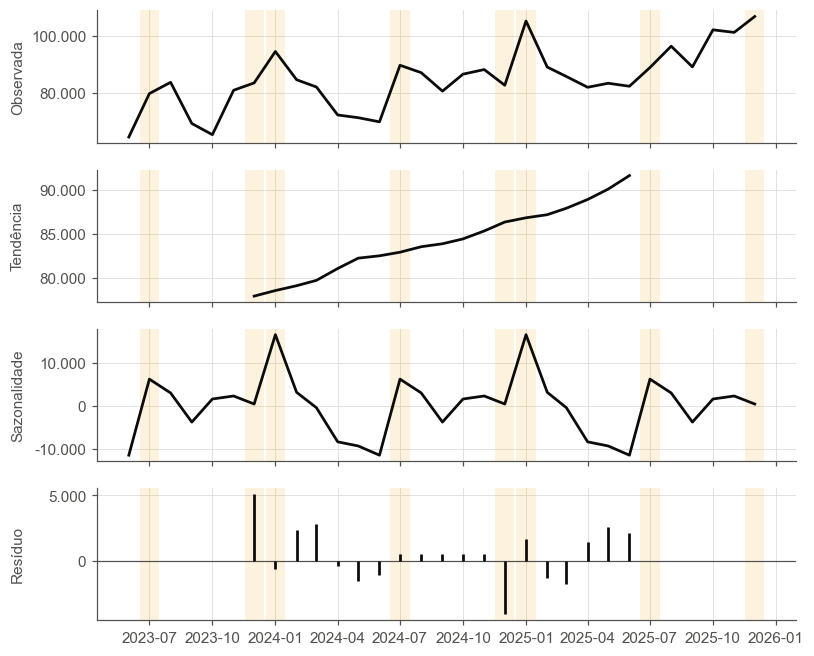

In [4]:
from statsmodels.tsa.seasonal import seasonal_decompose
dec = seasonal_decompose(b2, model="additive", period=12)
T, S, R = dec.trend, dec.seasonal, dec.resid
ok = R.notna()
var = lambda x: float(np.var(x, ddof=1))
# Força da sazonalidade e da tendência (Hyndman; Athanasopoulos, 2021, seção 4.3)
Fs = max(0.0, 1 - var(R[ok]) / var((S + R)[ok]))
Ft = max(0.0, 1 - var(R[ok]) / var((T + R)[ok]))
RES["decomposicao"] = {"bloco": 2, "n": int(b2.size), "modelo": "aditivo", "periodo": 12,
                       "forca_sazonalidade": Fs, "forca_tendencia": Ft,
                       "tendencia_inicio": float(T.dropna().iloc[0]), "tendencia_fim": float(T.dropna().iloc[-1]),
                       "tendencia_inicio_mes": T.dropna().index[0].strftime("%Y-%m"),
                       "tendencia_fim_mes": T.dropna().index[-1].strftime("%Y-%m"),
                       "componente_sazonal": {MESES[i.month - 1]: float(v) for i, v in S.iloc[:12].items()}}
print(f"força da sazonalidade Fs = {Fs:.3f} | força da tendência Ft = {Ft:.3f}")
print(f"tendência: {T.dropna().iloc[0]:,.0f} ({RES['decomposicao']['tendencia_inicio_mes']}) -> "
      f"{T.dropna().iloc[-1]:,.0f} ({RES['decomposicao']['tendencia_fim_mes']})")

fig, axs = plt.subplots(4, 1, figsize=(8.2, 7.2), sharex=True)
partes = [("Observada", b2), ("Tendência", T), ("Sazonalidade", S), ("Resíduo", R)]
for ax, (nome, s) in zip(axs, partes):
    for d in b2.index[b2.index.month.isin([1, 7, 12])]:
        ax.axvspan(d - pd.Timedelta(days=14), d + pd.Timedelta(days=14), color=AMBAR, alpha=0.13, lw=0)
    if nome == "Resíduo":
        ax.axhline(0, color=TINTA2, lw=0.8)
        ax.vlines(s.index, 0, s.values, color=TINTA, lw=1.8)
    else:
        ax.plot(s.index, s.values, color=TINTA, lw=1.8)
    ax.set_ylabel(nome)
    ax.yaxis.set_major_formatter(milhar)
fig.align_ylabels(axs)
fig.savefig(SAIDA / "cap5_decomposicao.png")
plt.show()

## 4. Função de autocorrelação — bloco 2

defasagens significativas (95%): [1]
ACF lag 1 = 0.482 | lag 12 = 0.187 (limite 0.487)


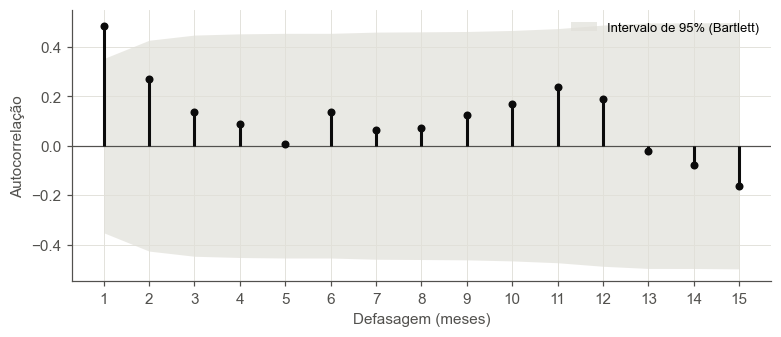

In [5]:
from statsmodels.tsa.stattools import acf
NLAGS = 15
valores, conf = acf(b2.values, nlags=NLAGS, alpha=0.05)
limite = conf[:, 1] - valores          # meia-largura da banda de Bartlett
RES["acf"] = {"nlags": NLAGS, "valores": {int(k): float(v) for k, v in enumerate(valores)},
              "limite_95": {int(k): float(v) for k, v in enumerate(limite)},
              "defasagens_significativas": [int(k) for k in range(1, NLAGS + 1) if abs(valores[k]) > limite[k]]}
print("defasagens significativas (95%):", RES["acf"]["defasagens_significativas"])
print(f"ACF lag 1 = {valores[1]:.3f} | lag 12 = {valores[12]:.3f} (limite {limite[12]:.3f})")

fig, ax = plt.subplots(figsize=(8.2, 3.2))
k = np.arange(1, NLAGS + 1)
ax.fill_between(k, -limite[1:], limite[1:], color=GRADE, alpha=0.7, lw=0, label="Intervalo de 95% (Bartlett)")
ax.axhline(0, color=TINTA2, lw=0.8)
ax.vlines(k, 0, valores[1:], color=TINTA, lw=2.0)
ax.scatter(k, valores[1:], color=TINTA, s=18, zorder=3)
ax.set_xticks(k)
ax.set_xlabel("Defasagem (meses)")
ax.set_ylabel("Autocorrelação")
ax.legend(loc="upper right", fontsize=8.5)
fig.savefig(SAIDA / "cap5_acf.png")
plt.show()

In [6]:
# M2 do parecer da orientadora (11/11/2026): a ACF acima usa o bloco 2 inteiro, que inclui o ano de teste (2025).
# Aqui ela é refeita só com a parte anterior ao teste, para mostrar que a escolha das defasagens não dependeu dela (Seção 5.1.4 do TCC).
b2_treino = b2[b2.index < "2025-01-01"]
NLAGS_T = 12
val_t, conf_t = acf(b2_treino.values, nlags=NLAGS_T, alpha=0.05)
lim_t = conf_t[:, 1] - val_t          # meia-largura da banda de Bartlett
RES["acf_sem_teste"] = {"periodo": f"{b2_treino.index[0]:%Y-%m} a {b2_treino.index[-1]:%Y-%m}", "n": int(b2_treino.size),
                        "nlags": NLAGS_T,
                        "valores": {int(k): float(v) for k, v in enumerate(val_t)},
                        "limite_95": {int(k): float(v) for k, v in enumerate(lim_t)},
                        "defasagens_significativas": [int(k) for k in range(1, NLAGS_T + 1) if abs(val_t[k]) > lim_t[k]]}
print(f"sem o teste ({RES['acf_sem_teste']['periodo']}, n = {b2_treino.size}): lag 1 = {val_t[1]:.3f}, "
      f"limite {lim_t[1]:.3f}; significativas: {RES['acf_sem_teste']['defasagens_significativas']}")

sem o teste (2023-06 a 2024-12, n = 19): lag 1 = 0.325, limite 0.450; significativas: []


## 5. Estacionariedade — ADF e KPSS (bloco 2)

As hipóteses dos dois testes são opostas, por isso são lidos em conjunto:
o **ADF** tem como hipótese nula a presença de raiz unitária (não estacionariedade);
o **KPSS** tem como hipótese nula a estacionariedade. Aplicados ao nível da série e à
primeira diferença. Com 31 observações o poder dos testes é limitado, o que é
registrado na interpretação.

In [7]:
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning

def testar(x, rotulo):
    adf = adfuller(x, autolag="AIC", regression="c")
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", InterpolationWarning)
        kp = kpss(x, regression="c", nlags="auto")
        truncado = any(issubclass(i.category, InterpolationWarning) for i in w)
    p_kpss = kp[1]
    p_kpss_txt = (f"≥ {p_kpss:.2f}" if truncado and p_kpss >= 0.1 else
                  f"≤ {p_kpss:.2f}" if truncado else f"{p_kpss:.3f}")
    return {"serie": rotulo, "n": int(len(x)),
            "adf_estatistica": float(adf[0]), "adf_valor_p": float(adf[1]), "adf_defasagens": int(adf[2]),
            "adf_critico_5": float(adf[4]["5%"]),
            "kpss_estatistica": float(kp[0]), "kpss_valor_p": float(p_kpss), "kpss_valor_p_texto": p_kpss_txt,
            "kpss_critico_5": float(kp[3]["5%"]),
            "adf_rejeita_raiz_unitaria_5": bool(adf[1] < 0.05),
            "kpss_rejeita_estacionariedade_5": bool(p_kpss < 0.05)}

testes = [testar(b2.values, "nível"), testar(b2.diff().dropna().values, "primeira diferença")]
RES["estacionariedade"] = testes
pd.DataFrame(testes).set_index("serie")[["n", "adf_estatistica", "adf_valor_p", "kpss_estatistica",
                                          "kpss_valor_p_texto", "adf_rejeita_raiz_unitaria_5",
                                          "kpss_rejeita_estacionariedade_5"]]

,n,adf_estatistica,adf_valor_p,kpss_estatistica,kpss_valor_p_texto,adf_rejeita_raiz_unitaria_5,kpss_rejeita_estacionariedade_5
serie,,,,,,,
nível,31,-2.725383,6.974798e-02,0.666160,0.017,False,True
primeira diferença,30,-7.000007,7.363526e-10,0.129648,≥ 0.10,True,False


In [8]:
(SAIDA / "caracterizacao.json").write_text(json.dumps(RES, ensure_ascii=False, indent=1), encoding="utf-8")
print("gravado:", sorted(p.name for p in SAIDA.glob("cap5_*.png")), "+ caracterizacao.json")

gravado: ['cap5_acf.png', 'cap5_decomposicao.png', 'cap5_importancia_rf.png', 'cap5_previsto_real.png', 'cap5_sementes.png'] + caracterizacao.json
